#Data Collection

import file

In [40]:
!curl -L -o ./higher-education-predictors-of-student-retention.zip https://www.kaggle.com/api/v1/datasets/download/thedevastator/higher-education-predictors-of-student-retention

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 89332  100 89332    0     0   271k      0 --:--:-- --:--:-- --:--:--  271k


unzip file

In [41]:
!unzip ./higher-education-predictors-of-student-retention.zip

Archive:  ./higher-education-predictors-of-student-retention.zip
replace dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

Creat Data frame

In [42]:
import pandas as pd
df = pd.read_csv("./dataset.csv")


vizualize data frame

In [43]:
df = pd.read_csv("./dataset.csv")

In [44]:
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,12,1,17,0,12,1,22,27,10,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,12,1,1,1,13,28,8,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,9,4,11,1,1,1,22,27,10,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,10,1,1,15,1,1,10,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,10,1,1,1,1,14,5,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


# PreProcessing

##import library

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

##check null values

In [46]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


handle null values

In [47]:
df = df.dropna()


##check duplicate values

In [48]:
df.duplicated().sum()

np.int64(0)

handle duplicate value

In [49]:
df = df.drop_duplicates()


##Target Preprocessing (Nakkavita N.K.P.P - IT24100244)

drop row values = "Enrolled"

In [50]:
df = df[df["Target"] != "Enrolled"]
df["Target"].value_counts()


,count
Target,
Graduate,2209
Dropout,1421


Distribution of Target after Dropping

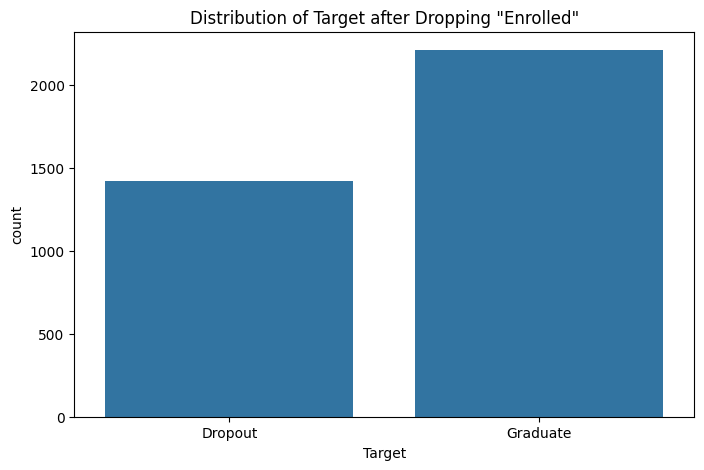

In [51]:
# Count plot
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Target')
plt.title('Distribution of Target after Dropping "Enrolled"')
plt.show()

##Encode categorical Variables (Jayaratne M. Y. De S. - IT24100284)

Encode the target columns Dropout=1 and graduate=0

In [52]:
df["Target"] = df["Target"].map({"Dropout": 1, "Graduate": 0})
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,1
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,0
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,1
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,0
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,0


percentage of each category

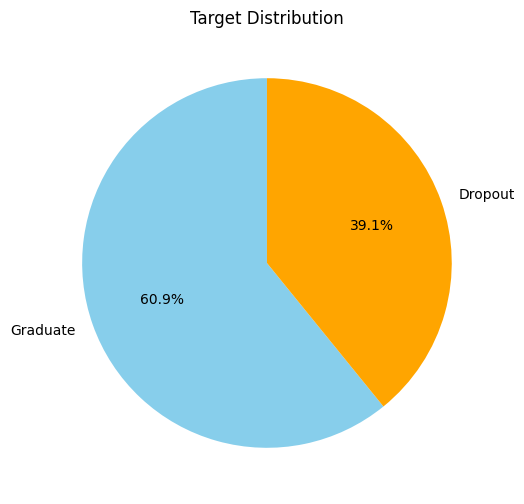

In [53]:
counts = df['Target'].value_counts()
labels = ['Graduate', 'Dropout']

plt.figure(figsize=(6,6))
plt.pie(counts, labels=labels, autopct='%1.1f%%', colors=['skyblue','orange'], startangle=90)
plt.title('Target Distribution')
plt.show()


##outlier Detection (Vinranga M. W. S. - IT24100374)

custom outlier remove for get value betweeen 0-20

In [54]:
# List of your curricular columns
curricular_cols = [
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
]

for col in curricular_cols:
    # Keep only rows where value is between 0 and 20 (inclusive)
    df = df[(df[col] >= 0) & (df[col] <= 20)]

Normal outlier remove

In [55]:
numeric_cols = ['Age at enrollment','Unemployment rate','Inflation rate', 'GDP']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove outliers
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    df_outlier_removed = df.copy()

Boxplot After remove outliers

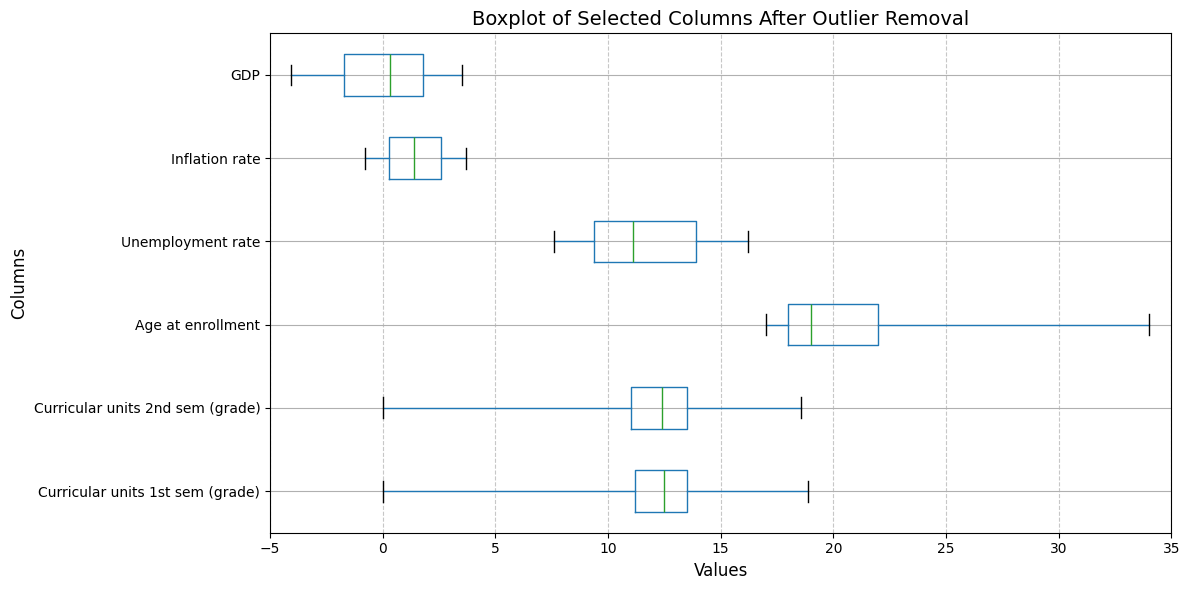

In [56]:
# Selected columns
selected_cols = [
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
    'Age at enrollment',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

plt.figure(figsize=(12, 6))

# Use whis=[0,100] to extend whiskers to min/max and avoid extra outlier dots
df[selected_cols].boxplot(vert=False, whis=[0, 100])

plt.title("Boxplot of Selected Columns After Outlier Removal", fontsize=14)
plt.xlabel("Values", fontsize=12)
plt.ylabel("Columns", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xlim(-5, 35)  # limit x-axis for curricular units
plt.tight_layout()
plt.show()



##Feature Scaling (Faazil M.M.M  - IT24100363)

In [57]:
from sklearn.preprocessing import StandardScaler

numeric_cols_to_scale = [
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP',
    'Age at enrollment'
]

scaler = StandardScaler()

df[numeric_cols_to_scale] = scaler.fit_transform(df[numeric_cols_to_scale])

In [58]:
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,-0.268806,-2.813848,-1.980450,-1.509342,-1.918718,-0.182246,-0.303683,0.126968,0.763116,1
1,1,6,1,11,1,1,1,1,3,4,...,-0.268806,-0.118641,-0.444891,0.452076,0.635676,-0.182246,0.867578,-1.104425,0.340296,0
2,1,1,5,5,1,1,1,22,27,10,...,-0.268806,-0.118641,-1.980450,-1.509342,-1.918718,-0.182246,-0.303683,0.126968,0.763116,1
3,1,8,2,15,1,1,1,23,27,6,...,-0.268806,-0.118641,0.578816,0.125173,0.398928,-0.182246,-0.832640,-1.466599,-1.399944,0
6,1,1,1,12,1,1,1,13,28,8,...,-0.268806,0.779761,0.066963,1.105882,0.762462,-0.182246,1.472100,1.141056,-1.818314,0
7,1,9,4,11,1,1,1,22,27,10,...,-0.268806,-0.567842,-0.700817,-1.509342,-1.918718,-0.182246,1.472100,1.141056,-1.818314,1
8,1,1,3,10,1,1,15,1,1,10,...,-0.268806,-0.118641,-0.188964,0.452076,0.724680,-0.182246,1.736578,-0.669816,-0.420781,0
9,1,1,1,10,1,1,1,1,14,5,...,-0.268806,-0.118641,1.602522,-0.855536,0.604525,-0.182246,-1.021553,0.126968,1.550897,1
10,1,1,1,14,1,1,1,23,14,6,...,-0.268806,-0.118641,-0.188964,0.125173,0.735360,-0.182246,0.867578,-1.104425,0.340296,0
11,1,1,1,12,1,1,1,13,28,10,...,-0.268806,0.779761,0.066963,0.778979,0.551123,-0.182246,0.414187,1.792969,-0.767939,0


save for future use when give new data

In [59]:
import joblib
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

histrograms after scaling

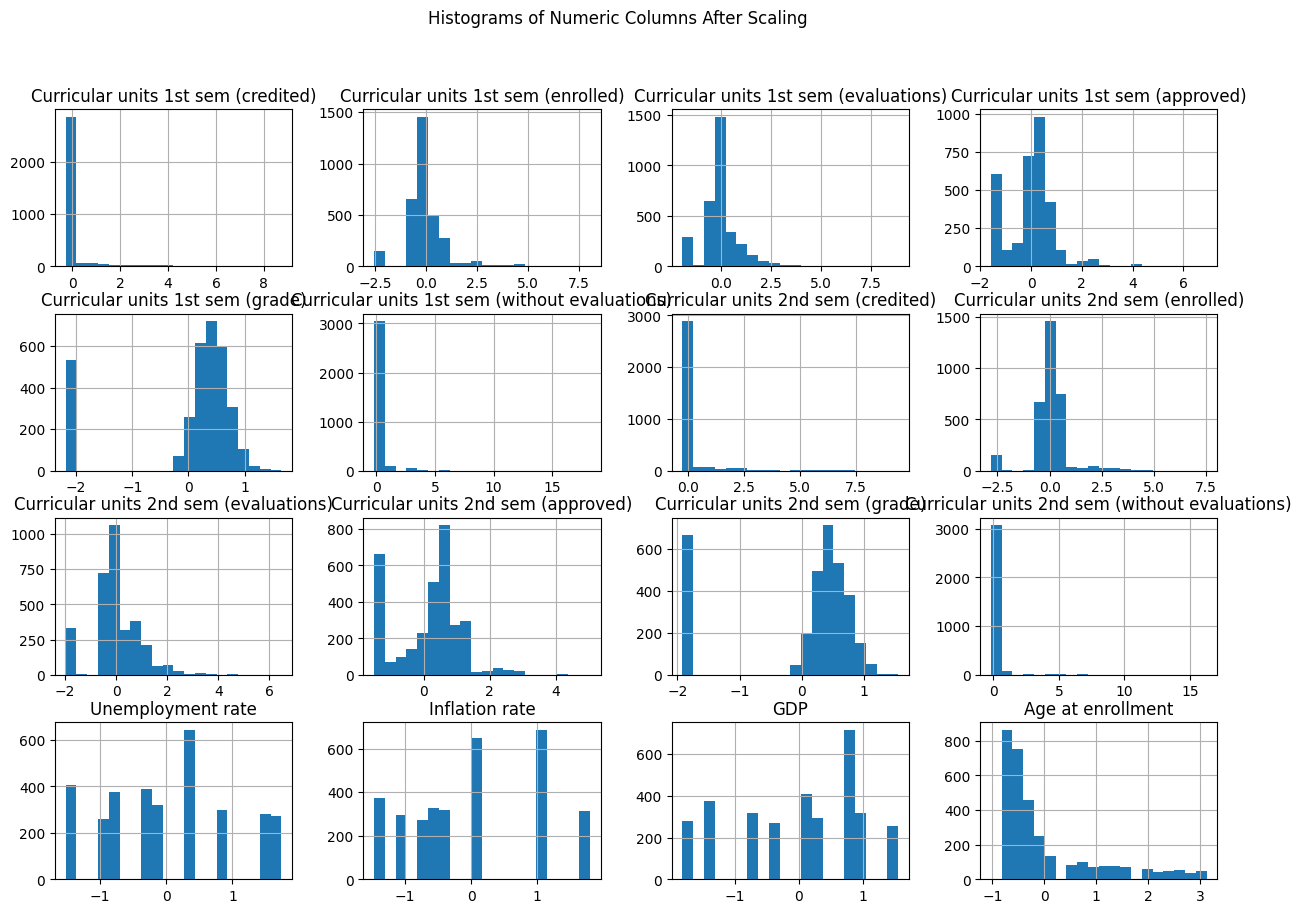

In [60]:
df[numeric_cols_to_scale].hist(bins=20, figsize=(15,10))
plt.suptitle("Histograms of Numeric Columns After Scaling")
plt.show()


##Balance Target column (Dissanayaka A.D.M.N.K. - IT24100225)

View colum count

In [61]:
df["Target"].value_counts()

,count
Target,
0,2057
1,1184


over sampling

In [62]:
from sklearn.utils import resample
# Separate classes
df_majority = df[df["Target"] == 0]
df_minority = df[df["Target"] == 1]

# Upsample minority class (1)
df_minority_upsampled = resample(
    df_minority,
    replace=True,                # sample with replacement
    n_samples=len(df_majority),  # match majority class size
    random_state=42
)

# Combine majority class with upsampled minority
df_balanced = pd.concat([df_majority, df_minority_upsampled])

# Shuffle dataset
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

# Check new class distribution
print(df_balanced['Target'].value_counts())


Target
0    2057
1    2057
Name: count, dtype: int64


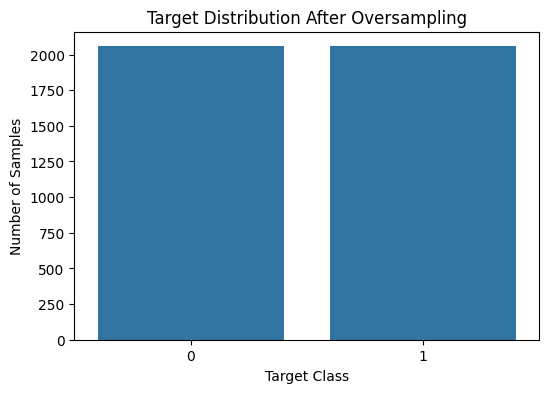

In [63]:
plt.figure(figsize=(6,4))
sns.countplot(x='Target', data=df_balanced)
plt.title("Target Distribution After Oversampling")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()





##Feature Selection (Weerasingha P. M. P. L. - IT24100316)

Correlation check

In [64]:
# Numeric features only
X_num = df_balanced[numeric_cols_to_scale]
y = df_balanced['Target']

# Add target as column to compute correlation
df_corr = X_num.copy()
df_corr['Target'] = y

# Pearson correlation
corr_matrix = df_corr.corr()
target_corr = corr_matrix['Target'].drop('Target')  # correlations of each feature with target

# Select top 10 features by absolute correlation
top_numeric_features = target_corr.abs().sort_values(ascending=False).head(10).index
print("Top numeric features by correlation:", top_numeric_features)


Top numeric features by correlation: Index(['Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)', 'Age at enrollment',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (without evaluations)',
       'Curricular units 1st sem (without evaluations)'],
      dtype='object')


find catagorical columns

In [65]:
# All columns in dataframe except numeric columns and target
categorical_encoded_cols = [col for col in df_balanced.columns
                            if col not in numeric_cols_to_scale + ['Target']]

print("Categorical columns for encoding / Chi-Square:", categorical_encoded_cols)


Categorical columns for encoding / Chi-Square: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']


chi squre test

In [66]:

from sklearn.feature_selection import SelectKBest, chi2

X_cat = df_balanced[categorical_encoded_cols]
y = df_balanced['Target']

chi_selector = SelectKBest(score_func=chi2, k=10)
X_cat_selected = chi_selector.fit_transform(X_cat, y)

selected_cat_features = X_cat.columns[chi_selector.get_support()]
print("Top categorical features by Chi-Square:", selected_cat_features)



Top categorical features by Chi-Square: Index(['Application mode', 'Application order', 'Previous qualification',
       'Mother's occupation', 'Father's occupation', 'Displaced', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder'],
      dtype='object')


selected fetures and make new dataset

In [67]:
# Define the selected features
categorical_features = [
    'Course',
    'Marital status',
    'Displaced',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'Daytime/evening attendance'
]

numeric_features = [
    'Curricular units 2nd sem (grade)',
    'Curricular units 1st sem (grade)',
    'Age at enrollment'
]

target_col = ['Target']

# Combine all into a list
selected_columns = categorical_features + numeric_features + target_col

# Create the new processed DataFrame
processed_data_set = df_balanced[selected_columns].copy()

#save processed dataset
processed_data_set.to_csv("processed_data_set.csv", index=False)


In [68]:
processed_data_set.head()

,Course,Marital status,Displaced,Tuition fees up to date,Gender,Scholarship holder,Daytime/evening attendance,Curricular units 2nd sem (grade),Curricular units 1st sem (grade),Age at enrollment,Target
0,3,1,0,1,0,0,0,0.230711,0.255139,2.639341,0
1,9,1,0,1,0,1,1,0.286783,0.092306,-0.786020,0
2,12,2,0,1,0,0,1,-1.918718,-2.187361,2.150004,1
3,12,1,1,1,0,1,1,0.494458,0.283126,-0.541351,0
4,9,1,0,0,0,1,1,0.230711,0.458681,-0.296682,1


use heat map for show relationships between every feature and the target

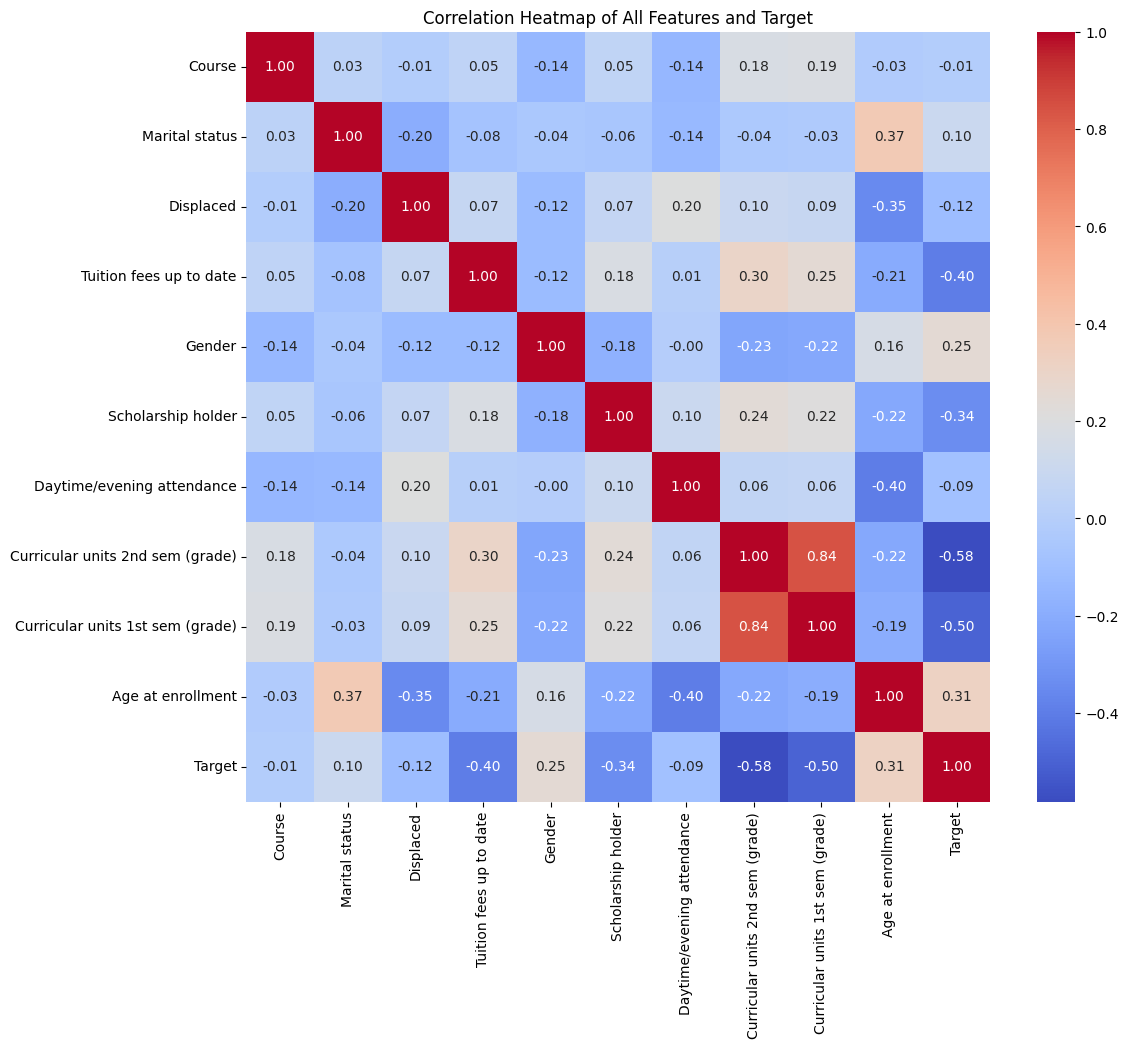

In [69]:
# All feature columns + target
all_cols = processed_data_set.columns

# Compute correlation matrix
corr_matrix = processed_data_set[all_cols].corr()

# Plot heatmap
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap of All Features and Target")
plt.show()


#Model Design & Implementation & Comparison

Models Selected

1. Logistic Regression
2. Random Forest
3. Decision Tree
4. SVM
5. K-Nearest Neighbors (KNN)
6. XGBoost

##split data for traning

In [70]:
from sklearn.model_selection import train_test_split


# Load preprocessed dataset
processed_data_set = pd.read_csv("processed_data_set.csv")
print(" Dataset loaded. Shape:", processed_data_set.shape)

# Separate features and target
X = processed_data_set.drop('Target', axis=1)
y = processed_data_set['Target']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,          # 20% for testing
    random_state=42,        # reproducible split
    stratify=y              # preserves class distribution
)

print(" Train/Test split done")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


 Dataset loaded. Shape: (4114, 11)
 Train/Test split done
Training samples: 3291, Testing samples: 823


##XGBoost

###libs

In [71]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np


###Traine without Hyperparameter Tuning

Baseline Test Accuracy: 0.9162

Classification Report (Baseline):
               precision    recall  f1-score   support

           0       0.92      0.92      0.92       412
           1       0.92      0.91      0.92       411

    accuracy                           0.92       823
   macro avg       0.92      0.92      0.92       823
weighted avg       0.92      0.92      0.92       823



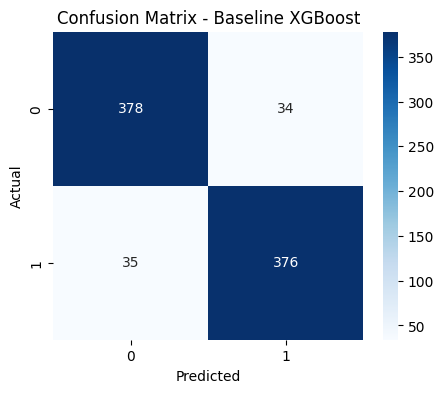

In [72]:
#Traine
xgb_base = XGBClassifier(eval_metric='logloss', random_state=42)
xgb_base.fit(X_train, y_train)

# Predictions
y_pred_xgb_base = xgb_base.predict(X_test)

# Evaluation
acc_xgb_base = accuracy_score(y_test, y_pred_xgb_base)
print(f"Baseline Test Accuracy: {acc_xgb_base:.4f}")
print("\nClassification Report (Baseline):\n", classification_report(y_test, y_pred_xgb_base))

# Confusion Matrix
cm_xgb_base = confusion_matrix(y_test, y_pred_xgb_base)
plt.figure(figsize=(5,4))
sns.heatmap(cm_xgb_base, annot=True, fmt='d', cmap='Blues', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Baseline XGBoost")
plt.show()

###Hyperparameter Tuning (RandomizedSearchCV)

In [73]:
param_dist_xgb = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2, 0.3],
    'reg_alpha': [0, 0.01, 0.1],
    'reg_lambda': [1, 1.5, 2]
}

xgb_random = RandomizedSearchCV(
    XGBClassifier(eval_metric='logloss', random_state=42),
    param_distributions=param_dist_xgb,
    n_iter=30,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

xgb_random.fit(X_train, y_train)
print("Best Parameters Found:", xgb_random.best_params_)

# Best tuned model
best_xgb = xgb_random.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters Found: {'subsample': 0.6, 'reg_lambda': 1.5, 'reg_alpha': 0.01, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.7}


eveluate tuned model


Tuned Test Accuracy: 0.9222

Classification Report (Tuned):
               precision    recall  f1-score   support

           0       0.93      0.92      0.92       412
           1       0.92      0.93      0.92       411

    accuracy                           0.92       823
   macro avg       0.92      0.92      0.92       823
weighted avg       0.92      0.92      0.92       823



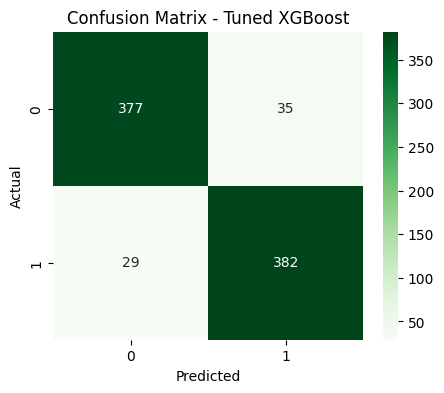

In [74]:
y_pred_xgb_tuned = best_xgb.predict(X_test)
acc_xgb_tuned = accuracy_score(y_test, y_pred_xgb_tuned)
print(f"\nTuned Test Accuracy: {acc_xgb_tuned:.4f}")
print("\nClassification Report (Tuned):\n", classification_report(y_test, y_pred_xgb_tuned))

# Confusion Matrix - Tuned
cm_xgb_tuned = confusion_matrix(y_test, y_pred_xgb_tuned)
plt.figure(figsize=(5,4))
sns.heatmap(cm_xgb_tuned, annot=True, fmt='d', cmap='Greens', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

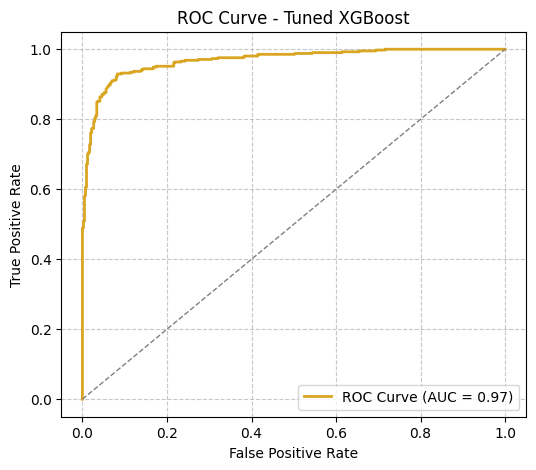

In [76]:
from sklearn.metrics import roc_curve, auc
# Get predicted probabilities for the positive class
y_prob_xgb_tuned = best_xgb.predict_proba(X_test)[:, 1]

# Compute ROC curve
fpr_xgb, tpr_xgb, thresholds_xgb = roc_curve(y_test, y_prob_xgb_tuned)

# Compute AUC
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# Plot ROC Curve
plt.figure(figsize=(6,5))
plt.plot(fpr_xgb, tpr_xgb, color='goldenrod', lw=2, label=f'ROC Curve (AUC = {roc_auc_xgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned XGBoost')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

###Cross validation

In [77]:
cv_scores_xgb = cross_val_score(best_xgb, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)
print("\nCross-validation scores:", np.round(cv_scores_xgb, 4))
print(f"Mean CV Accuracy: {cv_scores_xgb.mean():.4f} ± {cv_scores_xgb.std():.4f}")


Cross-validation scores: [0.9044 0.9225 0.9225 0.9271 0.9301]
Mean CV Accuracy: 0.9213 ± 0.0089


###test overfitting

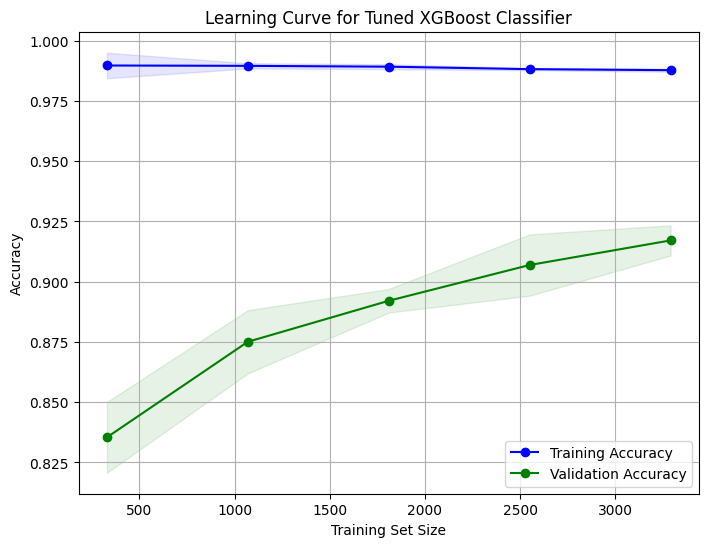

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from xgboost import XGBClassifier

# Best tuned XGBoost model
best_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.2,
    max_depth=7,
    subsample=0.6,
    colsample_bytree=0.7,
    gamma=0,
    reg_alpha=0.01,
    reg_lambda=1.5,
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False,
    eval_metric='mlogloss'
)

# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    best_xgb, X, y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

# Compute mean and std
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot learning curve
plt.figure(figsize=(8,6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.plot(train_sizes, test_mean, 'o-', color='green', label='Validation Accuracy')

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.1)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, color='green', alpha=0.1)

plt.title('Learning Curve for Tuned XGBoost Classifier')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True)
plt.show()
